#  <center>Taller de Aprendizaje Automatico</center>
##  <center>Paso 2: Cargar e inspeccionar los datos</center>
### <center>Descarga e inspeccion inicial del dataset Higgs Boson</center>

Este notebook deja disponibles los archivos del challenge dentro de `data/higgs-boson/` y realiza una primera inspeccion estructural del dataset. La idea es resolver en un mismo lugar la preparacion inicial, la carga reproducible y la lectura preliminar de los datos antes de cualquier modelado.

## Configuracion de Kaggle

La siguiente celda localiza la raiz del proyecto, prepara `data/higgs-boson/` y configura la CLI de Kaggle si hace falta descargar los archivos. Si los datos ya estan disponibles localmente, el notebook puede seguir funcionando sin volver a bajarlos.

In [1]:
from __future__ import annotations

import importlib.util
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "docs").is_dir():
            return candidate
    raise RuntimeError("No se pudo resolver la raiz del proyecto desde el directorio actual.")


project_root = find_project_root()
keys_dir = project_root / "keys"
kaggle_file = keys_dir / "kaggle.json"
data_dir = project_root / "data" / "higgs-boson"
data_dir.mkdir(parents=True, exist_ok=True)

required_files = [
    "training.csv",
    "test.csv",
    "random_submission.csv",
    "HiggsBosonCompetition_AMSMetric_rev1.py",
]
files_ready = all((data_dir / name).exists() for name in required_files)

if kaggle_file.exists() and os.name != "nt":
    kaggle_file.chmod(0o600)

if kaggle_file.exists():
    os.environ["KAGGLE_CONFIG_DIR"] = str(keys_dir.resolve())

kaggle_cli = shutil.which("kaggle")
if kaggle_cli is None:
    candidate_paths = [
        Path.home() / ".local" / "bin" / "kaggle",
        Path(sys.executable).resolve().parent / "kaggle",
    ]
    kaggle_cli = next((str(candidate) for candidate in candidate_paths if candidate.exists()), None)

if not files_ready and not kaggle_file.exists():
    raise FileNotFoundError(
        f"No se encontro {kaggle_file.resolve()}. Guarde ahi su kaggle.json o deje los datos ya descargados en {data_dir.resolve()}."
    )

print(f"project_root = {project_root}")
print(f"data_dir = {data_dir.resolve()}")
print(f"files_ready = {files_ready}")
print(f"kaggle_file_present = {kaggle_file.exists()}")
print(f"kaggle_cli = {kaggle_cli}")

project_root = /home/santig14/fing/taa/1_TallerAA
data_dir = /home/santig14/fing/taa/1_TallerAA/data/higgs-boson
files_ready = True
kaggle_file_present = True
kaggle_cli = /home/santig14/.local/bin/kaggle


## Descarga y descompresion

Si los archivos principales ya existen en `data/higgs-boson/`, esta celda no vuelve a descargar nada. En caso contrario, descarga el paquete oficial de Kaggle y descomprime tanto el archivo principal como los `.zip` internos.

In [2]:
competition = "higgs-boson"
archive_path = data_dir / f"{competition}.zip"

if all((data_dir / name).exists() for name in required_files):
    print("Los archivos principales ya estan disponibles. Se omite la descarga.")
else:
    if kaggle_cli is None:
        raise FileNotFoundError(
            "No se encontro la CLI de kaggle para descargar los datos."
        )

    subprocess.run(
        [
            kaggle_cli,
            "competitions",
            "download",
            "-c",
            competition,
            "-p",
            str(data_dir),
        ],
        check=True,
    )

    with zipfile.ZipFile(archive_path, "r") as zip_ref:
        zip_ref.extractall(data_dir)

    for zip_path in sorted(data_dir.glob("*.zip")):
        if zip_path.name == archive_path.name:
            continue
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(data_dir)

    print("Descarga y descompresion finalizadas.")

Los archivos principales ya estan disponibles. Se omite la descarga.


## Verificacion de descarga

In [3]:
missing_files = [name for name in required_files if not (data_dir / name).exists()]

if missing_files:
    raise FileNotFoundError(
        "Faltan archivos esperados luego de la descarga: " + ", ".join(missing_files)
    )

print("Archivos principales disponibles:")
for name in required_files:
    print(f"- {data_dir / name}")

Archivos principales disponibles:
- /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/training.csv
- /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/test.csv
- /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/random_submission.csv
- /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/HiggsBosonCompetition_AMSMetric_rev1.py


## Inspeccion inicial de los datos

En esta parte se realiza la carga reproducible de `training.csv` y `test.csv`, y luego se inspecciona su estructura para entender la forma del problema antes de cualquier modelado.

## Carga reproducible

Se cargan los datos desde `data/higgs-boson/` usando rutas relativas al proyecto, de forma que el notebook pueda ejecutarse nuevamente sin depender del estado previo de la sesion.

In [4]:
import os

os.environ["MPLCONFIGDIR"] = str((data_dir / ".mplconfig").resolve())
(data_dir / ".mplconfig").mkdir(exist_ok=True)

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

train_path = data_dir / "training.csv"
test_path = data_dir / "test.csv"

train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)

shape_summary = pd.DataFrame(
    {
        "dataset": ["training", "test"],
        "rows": [len(train_data), len(test_data)],
        "columns": [train_data.shape[1], test_data.shape[1]],
    }
)

display(shape_summary)
print(f"training path = {train_path}")
print(f"test path = {test_path}")

,dataset,rows,columns
0,training,250000,33
1,test,550000,31


training path = /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/training.csv
test path = /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/test.csv


## Vista general del dataset

Primero se revisan las dimensiones, los nombres de las columnas, los tipos de datos y las primeras filas para obtener una lectura global del contenido.

In [5]:
all_columns = sorted(set(train_data.columns).union(test_data.columns))
columns_overview = pd.DataFrame(index=all_columns)
columns_overview["in_training"] = [col in train_data.columns for col in all_columns]
columns_overview["in_test"] = [col in test_data.columns for col in all_columns]
columns_overview["training_dtype"] = [str(train_data[col].dtype) if col in train_data.columns else "-" for col in all_columns]
columns_overview["test_dtype"] = [str(test_data[col].dtype) if col in test_data.columns else "-" for col in all_columns]

display(columns_overview)

print("Columnas solo en training:", sorted(set(train_data.columns) - set(test_data.columns)))
print("Columnas solo en test:", sorted(set(test_data.columns) - set(train_data.columns)))
print("\nResumen estructural de training:")
train_data.info()
print("\nResumen estructural de test:")
test_data.info()


,in_training,in_test,training_dtype,test_dtype
DER_deltaeta_jet_jet,True,True,float64,float64
DER_deltar_tau_lep,True,True,float64,float64
DER_lep_eta_centrality,True,True,float64,float64
DER_mass_MMC,True,True,float64,float64
DER_mass_jet_jet,True,True,float64,float64
DER_mass_transverse_met_lep,True,True,float64,float64
DER_mass_vis,True,True,float64,float64
DER_met_phi_centrality,True,True,float64,float64
DER_prodeta_jet_jet,True,True,float64,float64
DER_pt_h,True,True,float64,float64


Columnas solo en training: ['Label', 'Weight']
Columnas solo en test: []

Resumen estructural de training:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   EventId                      250000 non-null  int64  
 1   DER_mass_MMC                 250000 non-null  float64
 2   DER_mass_transverse_met_lep  250000 non-null  float64
 3   DER_mass_vis                 250000 non-null  float64
 4   DER_pt_h                     250000 non-null  float64
 5   DER_deltaeta_jet_jet         250000 non-null  float64
 6   DER_mass_jet_jet             250000 non-null  float64
 7   DER_prodeta_jet_jet          250000 non-null  float64
 8   DER_deltar_tau_lep           250000 non-null  float64
 9   DER_pt_tot                   250000 non-null  float64
 10  DER_sum_pt                   250000 non-null  float64
 11  DER_pt_rat

In [6]:
print("Primeras filas de training:")
display(train_data.head(3))

print("Primeras filas de test:")
display(test_data.head(3))

Primeras filas de training:


,EventId,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,DER_sum_pt,DER_pt_ratio_lep_tau,DER_met_phi_centrality,DER_lep_eta_centrality,PRI_tau_pt,PRI_tau_eta,PRI_tau_phi,PRI_lep_pt,PRI_lep_eta,PRI_lep_phi,PRI_met,PRI_met_phi,PRI_met_sumet,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt,Weight,Label
0,100000,138.470,51.655,97.827,27.980,0.91,124.711,2.666,3.064,41.928,197.760,1.582,1.396,0.2,32.638,1.017,0.381,51.626,2.273,-2.414,16.824,-0.277,258.733,2,67.435,2.150,0.444,46.062,1.24,-2.475,113.497,0.002653,s
1,100001,160.937,68.768,103.235,48.146,-999.00,-999.000,-999.000,3.473,2.078,125.157,0.879,1.414,-999.0,42.014,2.039,-3.011,36.918,0.501,0.103,44.704,-1.916,164.546,1,46.226,0.725,1.158,-999.000,-999.00,-999.000,46.226,2.233584,b
2,100002,-999.000,162.172,125.953,35.635,-999.00,-999.000,-999.000,3.148,9.336,197.814,3.776,1.414,-999.0,32.154,-0.705,-2.093,121.409,-0.953,1.052,54.283,-2.186,260.414,1,44.251,2.053,-2.028,-999.000,-999.00,-999.000,44.251,2.347389,b


Primeras filas de test:


,EventId,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,DER_sum_pt,DER_pt_ratio_lep_tau,DER_met_phi_centrality,DER_lep_eta_centrality,PRI_tau_pt,PRI_tau_eta,PRI_tau_phi,PRI_lep_pt,PRI_lep_eta,PRI_lep_phi,PRI_met,PRI_met_phi,PRI_met_sumet,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt
0,350000,-999.000,79.589,23.916,3.036,-999.0,-999.0,-999.0,0.903,3.036,56.018,1.536,-1.404,-999.0,22.088,-0.540,-0.609,33.930,-0.504,-1.511,48.509,2.022,98.556,0,-999.000,-999.000,-999.000,-999.0,-999.0,-999.0,-0.000
1,350001,106.398,67.490,87.949,49.994,-999.0,-999.0,-999.0,2.048,2.679,132.865,1.777,-1.204,-999.0,30.716,-1.784,3.054,54.574,-0.169,1.795,21.093,-1.138,176.251,1,47.575,-0.553,-0.849,-999.0,-999.0,-999.0,47.575
2,350002,117.794,56.226,96.358,4.137,-999.0,-999.0,-999.0,2.755,4.137,97.600,1.096,-1.408,-999.0,46.564,-0.298,3.079,51.036,-0.548,0.336,19.461,-1.868,111.505,0,-999.000,-999.000,-999.000,-999.0,-999.0,-999.0,0.000


## Estadisticas basicas

Luego se exploran estadisticas descriptivas simples para las variables numericas, con el objetivo de detectar rangos, escalas distintas y valores atipicos evidentes.

,count,mean,std,min,25%,50%,75%,max
DER_deltaeta_jet_jet,250000.0,-708.421,454.481,-999.000,-999.000,-999.000,0.490,8.503
DER_deltar_tau_lep,250000.0,2.373,0.783,0.208,1.810,2.492,2.961,5.684
DER_lep_eta_centrality,250000.0,-708.985,453.597,-999.000,-999.000,-999.000,0.000,1.000
DER_mass_MMC,250000.0,-49.023,406.346,-999.000,78.101,105.012,130.606,1192.026
DER_mass_jet_jet,250000.0,-601.237,657.972,-999.000,-999.000,-999.000,83.446,4974.979
DER_mass_transverse_met_lep,250000.0,49.240,35.345,0.000,19.241,46.524,73.598,690.075
DER_mass_vis,250000.0,81.182,40.829,6.329,59.389,73.752,92.259,1349.351
DER_met_phi_centrality,250000.0,-0.128,1.194,-1.414,-1.371,-0.356,1.225,1.414
DER_prodeta_jet_jet,250000.0,-709.357,453.020,-999.000,-999.000,-999.000,-4.593,16.690
DER_pt_h,250000.0,57.896,63.656,0.000,14.069,38.468,79.169,2834.999


,Label,count,fraction
0,b,164333,0.6573
1,s,85667,0.3427


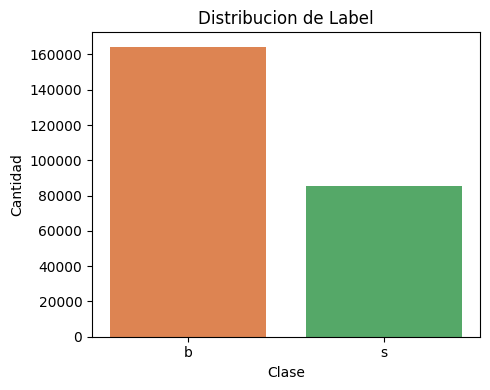

In [7]:
numeric_feature_columns = train_data.select_dtypes(include="number").columns.difference(["EventId", "Weight"])
train_numeric_summary = train_data[numeric_feature_columns].describe().T.round(3)
display(train_numeric_summary)

label_counts = train_data["Label"].value_counts().rename_axis("Label").reset_index(name="count")
label_counts["fraction"] = (label_counts["count"] / len(train_data)).round(4)
display(label_counts)

fig, ax = plt.subplots(figsize=(5, 4))
label_series = train_data["Label"].value_counts().sort_index()
ax.bar(label_series.index, label_series.values, color=["#DD8452", "#55A868"])
ax.set_title("Distribucion de Label")
ax.set_xlabel("Clase")
ax.set_ylabel("Cantidad")
plt.tight_layout()
plt.show()

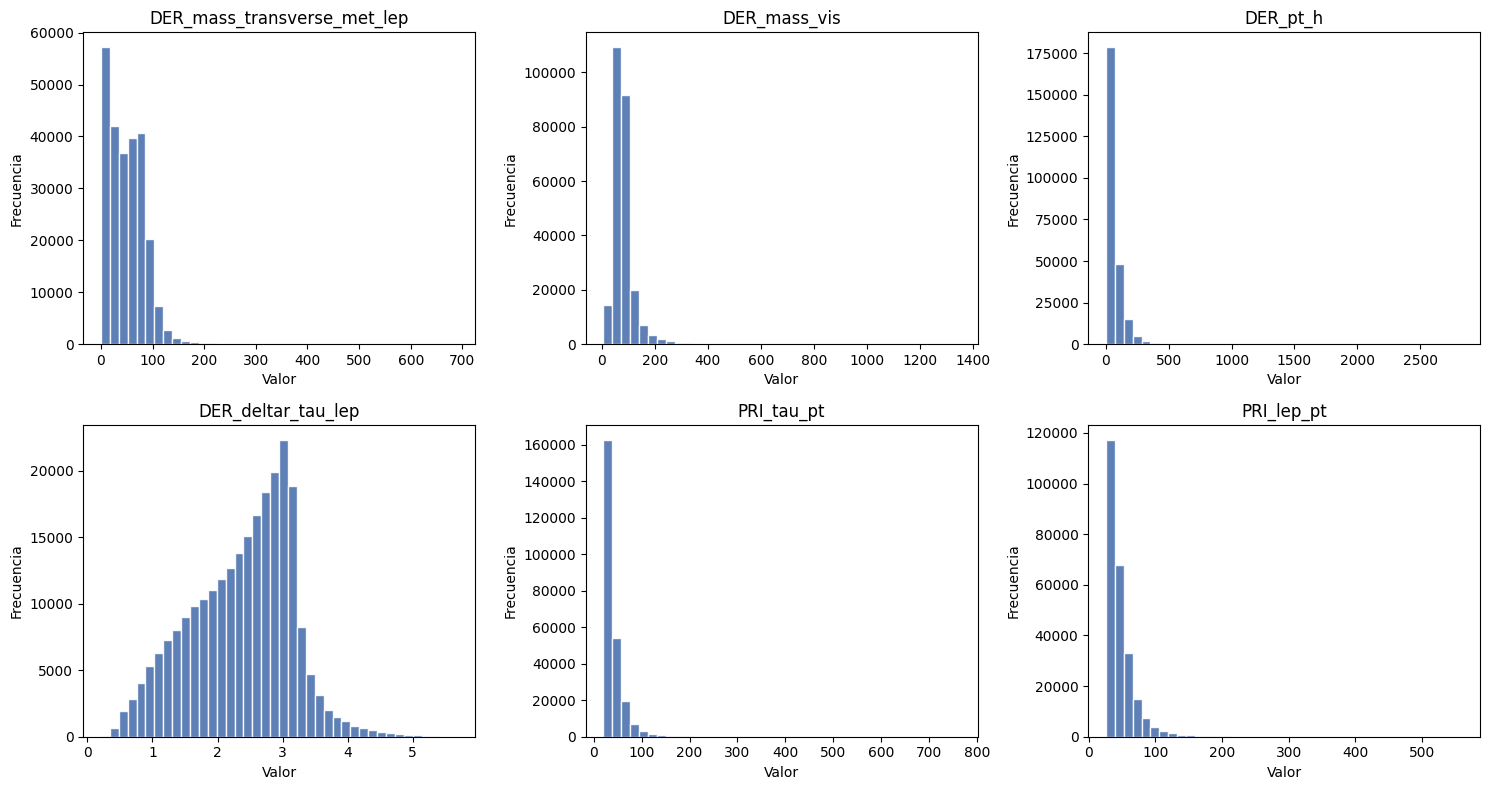

In [8]:
selected_columns = [
    "DER_mass_transverse_met_lep",
    "DER_mass_vis",
    "DER_pt_h",
    "DER_deltar_tau_lep",
    "PRI_tau_pt",
    "PRI_lep_pt",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.ravel(), selected_columns):
    ax.hist(train_data[column], bins=40, color="#4C72B0", edgecolor="white", alpha=0.9)
    ax.set_title(column)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

## Valores faltantes y marcadores especiales

A continuacion se cuantifican los valores faltantes por columna y se visualizan los marcadores `-999`, que en este dataset cumplen el rol de variables indefinidas para ciertos eventos.

,train_na_count,train_na_pct,train_minus_999_count,train_minus_999_pct,test_na_count,test_na_pct,test_minus_999_count,test_minus_999_pct,dtype_training,nunique_training
DER_deltaeta_jet_jet,0,0.0,177457,70.98,0.0,0.0,389872.0,70.89,float64,7087
DER_lep_eta_centrality,0,0.0,177457,70.98,0.0,0.0,389872.0,70.89,float64,1002
DER_mass_jet_jet,0,0.0,177457,70.98,0.0,0.0,389872.0,70.89,float64,68366
DER_prodeta_jet_jet,0,0.0,177457,70.98,0.0,0.0,389872.0,70.89,float64,16593
PRI_jet_subleading_eta,0,0.0,177457,70.98,0.0,0.0,389872.0,70.89,float64,8628
PRI_jet_subleading_phi,0,0.0,177457,70.98,0.0,0.0,389872.0,70.89,float64,6286
PRI_jet_subleading_pt,0,0.0,177457,70.98,0.0,0.0,389872.0,70.89,float64,42464
PRI_jet_leading_eta,0,0.0,99913,39.97,0.0,0.0,220156.0,40.03,float64,8558
PRI_jet_leading_phi,0,0.0,99913,39.97,0.0,0.0,220156.0,40.03,float64,6285
PRI_jet_leading_pt,0,0.0,99913,39.97,0.0,0.0,220156.0,40.03,float64,86590


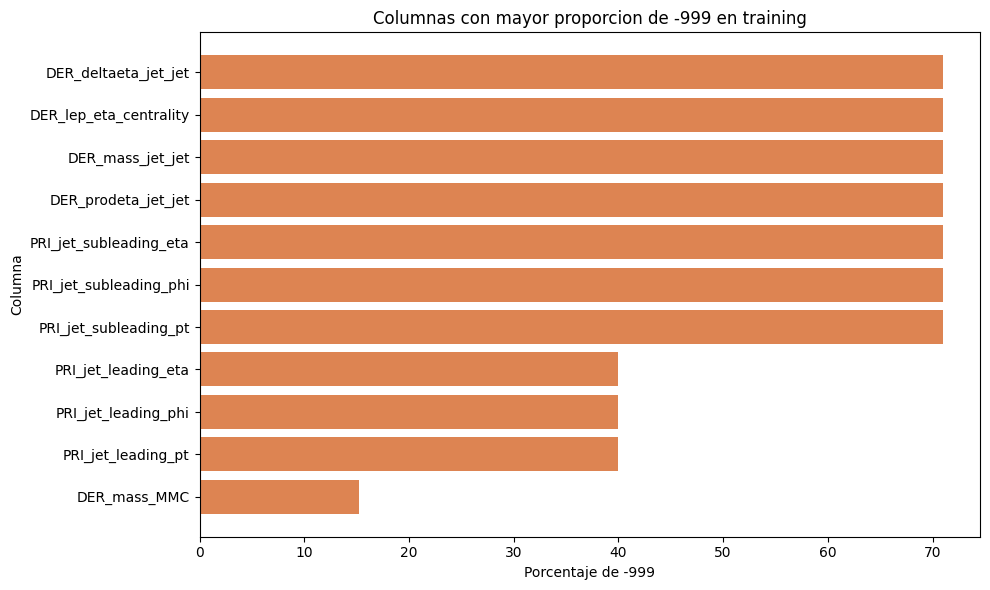

In [9]:
def build_missing_summary(df: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    summary = pd.DataFrame(index=df.columns)
    summary[f"{dataset_name}_na_count"] = df.isna().sum()
    summary[f"{dataset_name}_na_pct"] = (df.isna().sum() / len(df) * 100).round(2)
    summary[f"{dataset_name}_minus_999_count"] = df.eq(-999).sum()
    summary[f"{dataset_name}_minus_999_pct"] = (df.eq(-999).sum() / len(df) * 100).round(2)
    return summary

missing_summary = build_missing_summary(train_data, "train").join(
    build_missing_summary(test_data, "test"),
    how="outer",
)
missing_summary["dtype_training"] = train_data.dtypes.astype(str)
missing_summary["nunique_training"] = train_data.nunique(dropna=False)

missing_sorted = missing_summary.sort_values(
    ["train_minus_999_pct", "train_na_pct"],
    ascending=False,
)
display(missing_sorted)

special_missing = missing_sorted[missing_sorted["train_minus_999_count"] > 0].head(12)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    special_missing.index[::-1],
    special_missing["train_minus_999_pct"][::-1],
    color="#DD8452",
)
ax.set_title("Columnas con mayor proporcion de -999 en training")
ax.set_xlabel("Porcentaje de -999")
ax.set_ylabel("Columna")
plt.tight_layout()
plt.show()

## Variables categoricas y discretas

Si aparecen variables con pocos valores unicos, se revisan sus categorias y frecuencias para detectar variables binarias, discretas o codificaciones especiales.

,nunique,dtype
Label,2,object
PRI_jet_num,4,int64


Frecuencias de PRI_jet_num:


,count
PRI_jet_num,
0,99913
1,77544
2,50379
3,22164


Frecuencias de Label:


,count
Label,
b,164333
s,85667


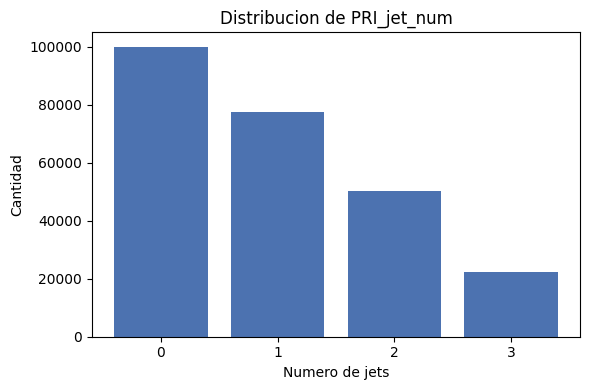

In [10]:
low_cardinality = pd.DataFrame(
    {
        "nunique": train_data.nunique(dropna=False),
        "dtype": train_data.dtypes.astype(str),
    }
).query("nunique <= 10")

display(low_cardinality.sort_values("nunique"))

for column in low_cardinality.index:
    print(f"Frecuencias de {column}:")
    display(train_data[column].value_counts(dropna=False).to_frame("count"))

fig, ax = plt.subplots(figsize=(6, 4))
jet_counts = train_data["PRI_jet_num"].value_counts().sort_index()
ax.bar(jet_counts.index.astype(str), jet_counts.values, color="#4C72B0")
ax.set_title("Distribucion de PRI_jet_num")
ax.set_xlabel("Numero de jets")
ax.set_ylabel("Cantidad")
plt.tight_layout()
plt.show()

## Columnas sospechosas

Por ultimo se buscan columnas con rol especial o comportamiento anomalo, como identificadores, columnas constantes, columnas casi vacias o variables que puedan anticipar la respuesta.

,dtype,nunique,na_pct,minus_999_pct,possible_id,special_role,constant,almost_empty,low_cardinality,possible_leakage,reason
Weight,float64,104096,0.0,0.00,False,True,False,False,False,True,"columna especial usada en la evaluacion, posib..."
Label,object,2,0.0,0.00,False,True,False,False,True,True,"variable objetivo, posible leakage si se usa c..."
EventId,int64,250000,0.0,0.00,True,True,False,False,False,False,identificador unico
DER_deltaeta_jet_jet,float64,7087,0.0,70.98,False,False,False,True,False,False,muchos -999
DER_mass_jet_jet,float64,68366,0.0,70.98,False,False,False,True,False,False,muchos -999
DER_prodeta_jet_jet,float64,16593,0.0,70.98,False,False,False,True,False,False,muchos -999
DER_lep_eta_centrality,float64,1002,0.0,70.98,False,False,False,True,False,False,muchos -999
PRI_jet_subleading_pt,float64,42464,0.0,70.98,False,False,False,True,False,False,muchos -999
PRI_jet_subleading_eta,float64,8628,0.0,70.98,False,False,False,True,False,False,muchos -999
PRI_jet_subleading_phi,float64,6286,0.0,70.98,False,False,False,True,False,False,muchos -999


EventId duplicados en training: 0
Columnas constantes: []


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
b,164333.0,2.501018,1.794235,0.064061,1.340468,2.080362,4.353313,7.822543
s,85667.0,0.008078,0.008231,0.001502,0.001503,0.001503,0.018636,0.018636


/tmp/ipykernel_52056/2054358194.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


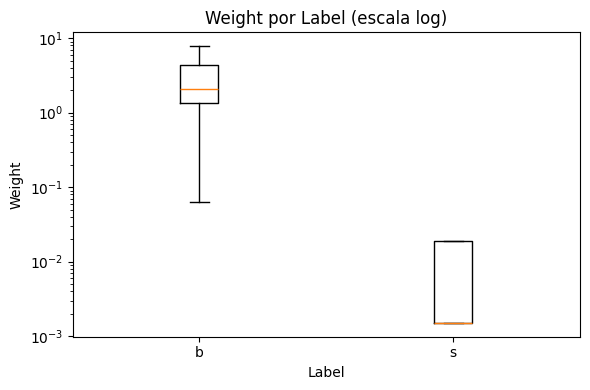

In [11]:
column_summary = pd.DataFrame(index=train_data.columns)
column_summary["dtype"] = train_data.dtypes.astype(str)
column_summary["nunique"] = train_data.nunique(dropna=False)
column_summary["na_pct"] = (train_data.isna().sum() / len(train_data) * 100).round(2)
column_summary["minus_999_pct"] = (train_data.eq(-999).sum() / len(train_data) * 100).round(2)
column_summary["possible_id"] = column_summary.index.str.contains("id", case=False)
column_summary["special_role"] = column_summary.index.isin(["EventId", "Weight", "Label"])
column_summary["constant"] = column_summary["nunique"] <= 1
column_summary["almost_empty"] = column_summary["minus_999_pct"] >= 70
column_summary["low_cardinality"] = column_summary["nunique"] <= 10
column_summary["possible_leakage"] = column_summary.index.isin(["Weight", "Label"])


def build_reason(column_name: str, row: pd.Series) -> str:
    reasons: list[str] = []
    if column_name == "EventId":
        reasons.append("identificador unico")
    if column_name == "Weight":
        reasons.append("columna especial usada en la evaluacion")
    if column_name == "Label":
        reasons.append("variable objetivo")
    if row["constant"]:
        reasons.append("constante")
    if row["almost_empty"]:
        reasons.append("muchos -999")
    if row["low_cardinality"] and column_name not in {"Label"}:
        reasons.append("baja cardinalidad")
    if row["possible_leakage"]:
        reasons.append("posible leakage si se usa como feature")
    return ", ".join(reasons)


column_summary["reason"] = [build_reason(column_name, column_summary.loc[column_name]) for column_name in column_summary.index]

suspicious_columns = column_summary[
    column_summary[["possible_id", "special_role", "constant", "almost_empty", "possible_leakage"]].any(axis=1)
].sort_values(["possible_leakage", "possible_id", "almost_empty"], ascending=False)

display(suspicious_columns)

print(f"EventId duplicados en training: {train_data['EventId'].duplicated().sum()}")
print(f"Columnas constantes: {column_summary.index[column_summary['constant']].tolist()}")

weight_by_label = train_data.groupby("Label")["Weight"].describe().round(6)
display(weight_by_label)

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(
    [train_data.loc[train_data["Label"] == "b", "Weight"], train_data.loc[train_data["Label"] == "s", "Weight"]],
    labels=["b", "s"],
    showfliers=False,
)
ax.set_yscale("log")
ax.set_title("Weight por Label (escala log)")
ax.set_xlabel("Label")
ax.set_ylabel("Weight")
plt.tight_layout()
plt.show()

    ## Hallazgos iniciales

- `training.csv` contiene `250000` filas y `33` columnas, mientras que `test.csv` contiene `550000` filas y `31` columnas.
- No aparecen valores `NaN` reales en ninguno de los dos conjuntos, pero varias columnas usan `-999` como marcador de variable indefinida.
- Las columnas mas afectadas por `-999` son sobre todo variables derivadas y variables asociadas a jets, en especial las subleading y algunas `DER_*`.
- `Label` es la unica variable categorica del conjunto de entrenamiento y esta desbalanceada a favor de `b` respecto de `s`.
- `PRI_jet_num` es una variable discreta con cuatro valores posibles (`0`, `1`, `2`, `3`) y ayuda a entender por que algunas columnas de jets quedan indefinidas.
- `EventId` funciona como identificador unico, mientras que `Weight` y `Label` deben tratarse como columnas especiales y no como features de entrada.